<a href="https://colab.research.google.com/github/Fauzi455/PembelajaranMesin_2026/blob/main/JS-08/TUGAS/Tugas%20Lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TUGAS LAB 1

In [1]:
from google.colab import files
uploaded = files.upload()

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset.csv


In [17]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering

df = pd.read_csv('CC_Customer_Dataset.csv')
print(df.head())

features = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]
X = df[features]

#standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341             50000                   7   
3      4         40496             30000                   5   
4      5         47437            100000                   6   

   Total_visits_bank  Total_visits_online  Total_calls_made  
0                  1                    1                 0  
1                  0                   10                 9  
2                  1                    3                 4  
3                  1                    1                 4  
4                  0                   12                 3  


Buatlah model klasterisasi dengan menggunakan Agglomerative Clustering dengan seluruh variabel yang dapat digunakan.

In [19]:
#menggunakan n_clusters=3, metric euclidean, dan linkage ward
agg_model = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')

#melakukan fitting dan prediksi label klaster
df['Cluster'] = agg_model.fit_predict(X_scaled)

#menampilkan distribusi jumlah data pada tiap klaster
print(df['Cluster'].value_counts())

Cluster
0    385
1    225
2     50
Name: count, dtype: int64


Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_credit_card. Tunjukkan bentuk cluster-nya berdasarkan dua fitur tersebut.

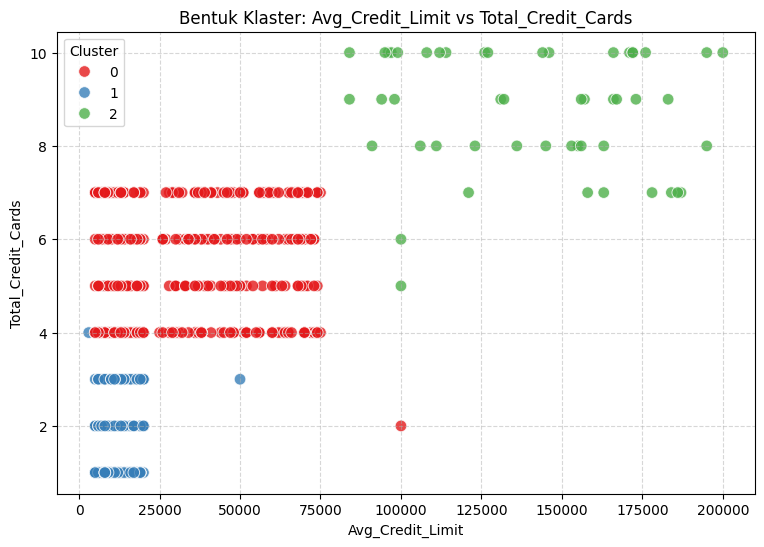

In [20]:
#membuat visualisasi scatterplot
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='Cluster',
    palette='Set1',
    s=70,
    alpha=0.8
)

plt.title('Bentuk Klaster: Avg_Credit_Limit vs Total_Credit_Cards', fontsize=12)
plt.xlabel('Avg_Credit_Limit', fontsize=10)
plt.ylabel('Total_Credit_Cards', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Cluster')
plt.show()

Tentukan nilai silhouette score dan DBI dari model.

In [21]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

#menghitung silhouette score
sil_score = silhouette_score(X_scaled, df['Cluster'])

#menghitung Davies-Bouldin Index (DBI)
dbi_score = davies_bouldin_score(X_scaled, df['Cluster'])

#menampilkan hasil evaluasi
print(f"Nilai Silhouette Score : {sil_score:.4f}")
print(f"Nilai Davies-Bouldin Index (DBI) : {dbi_score:.4f}")

Nilai Silhouette Score : 0.5148
Nilai Davies-Bouldin Index (DBI) : 0.6810
